In [1]:
#Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
#Load Dataset, copy and view
tire_wear = pd.read_csv("tire_wear_dataset.csv")
tire_wear_copy = tire_wear.copy()
tire_wear.head(10)

,Time_s,Speed_kmh,Load_N,TireTemp_C,SlipAngle_deg,Pressure_kPa,WearRate_mm_per_km
0,0,69.963210,4926.094938,36.187432,1.689351,236.579091,0.092582
1,1,116.057145,3252.419895,84.153174,2.785903,192.203123,0.186598
2,2,98.559515,3484.886142,60.315142,1.770105,226.103069,0.143290
3,3,87.892679,5695.662566,79.587448,0.887025,228.537204,0.166203
4,4,52.481491,4819.287179,49.202976,1.206359,213.930454,0.103312
5,5,52.479562,3027.591155,83.731394,4.607788,238.915539,0.162211
6,6,44.646689,3304.414629,53.352101,2.063337,254.749361,0.107099
7,7,109.294092,4990.505307,30.650259,3.642699,254.045481,0.108291
8,8,88.089201,3015.184752,84.322919,5.034173,216.067150,0.179633
9,9,96.645806,3482.424154,35.477201,6.903948,189.059044,0.111557


In [3]:
#Details about the dataset
tire_wear.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Time_s              200 non-null    int64  
 1   Speed_kmh           200 non-null    float64
 2   Load_N              200 non-null    float64
 3   TireTemp_C          200 non-null    float64
 4   SlipAngle_deg       200 non-null    float64
 5   Pressure_kPa        200 non-null    float64
 6   WearRate_mm_per_km  200 non-null    float64
dtypes: float64(6), int64(1)
memory usage: 11.1 KB


In [4]:
#Statistical Information about the dataset
tire_wear.describe(include="all")

,Time_s,Speed_kmh,Load_N,TireTemp_C,SlipAngle_deg,Pressure_kPa,WearRate_mm_per_km
count,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,99.500000,78.720499,4513.125407,61.240367,4.787711,217.076597,0.140687
std,57.879185,23.591314,879.003576,18.438528,2.788346,22.826624,0.030436
min,0.000000,40.441769,3015.184752,30.650259,0.181102,180.370562,0.069263
25%,49.750000,58.286593,3784.387501,45.331219,2.359733,196.752061,0.116842
50%,99.500000,79.558900,4624.919634,61.523969,4.671280,215.470741,0.139475
75%,149.250000,100.548769,5226.597944,78.666893,7.244063,235.198073,0.164378
max,199.000000,118.950955,5971.515426,89.983060,9.899602,259.749940,0.205251


In [5]:
#Checking for duplicates
tire_wear[tire_wear.duplicated()]

,Time_s,Speed_kmh,Load_N,TireTemp_C,SlipAngle_deg,Pressure_kPa,WearRate_mm_per_km


In [6]:
#Rounding the values to 3 decimal places
tire_wear = tire_wear.round(3)

In [7]:
#Changing the time column to time data type
tire_wear["Time_s"] = pd.to_timedelta(tire_wear["Time_s"],unit="s")

In [8]:
#Renaming the columns' head
tire_wear.columns = ["Time(s)","Speed(km/h)","Load(N)","Tire Temp(C)","Slip Angle(deg)","Pressure(kPa)","Wear Rate(mm/km)"]

In [9]:
#Verification for the change effected
tire_wear.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Time(s)           200 non-null    timedelta64[s]
 1   Speed(km/h)       200 non-null    float64       
 2   Load(N)           200 non-null    float64       
 3   Tire Temp(C)      200 non-null    float64       
 4   Slip Angle(deg)   200 non-null    float64       
 5   Pressure(kPa)     200 non-null    float64       
 6   Wear Rate(mm/km)  200 non-null    float64       
dtypes: float64(6), timedelta64[s](1)
memory usage: 11.1 KB


In [10]:
#Viewing the dataset for the time column
tire_wear.tail(5)

,Time(s),Speed(km/h),Load(N),Tire Temp(C),Slip Angle(deg),Pressure(kPa),Wear Rate(mm/km)
195,0 days 00:03:15,67.937,5792.272,58.438,8.721,187.327,0.136
196,0 days 00:03:16,98.076,5575.238,70.053,9.321,253.385,0.172
197,0 days 00:03:17,111.769,4286.982,40.339,5.651,190.945,0.123
198,0 days 00:03:18,110.967,5252.613,41.537,6.967,256.019,0.128
199,0 days 00:03:19,102.390,5263.629,32.452,9.225,215.680,0.120


<Figure size 2000x1500 with 0 Axes>

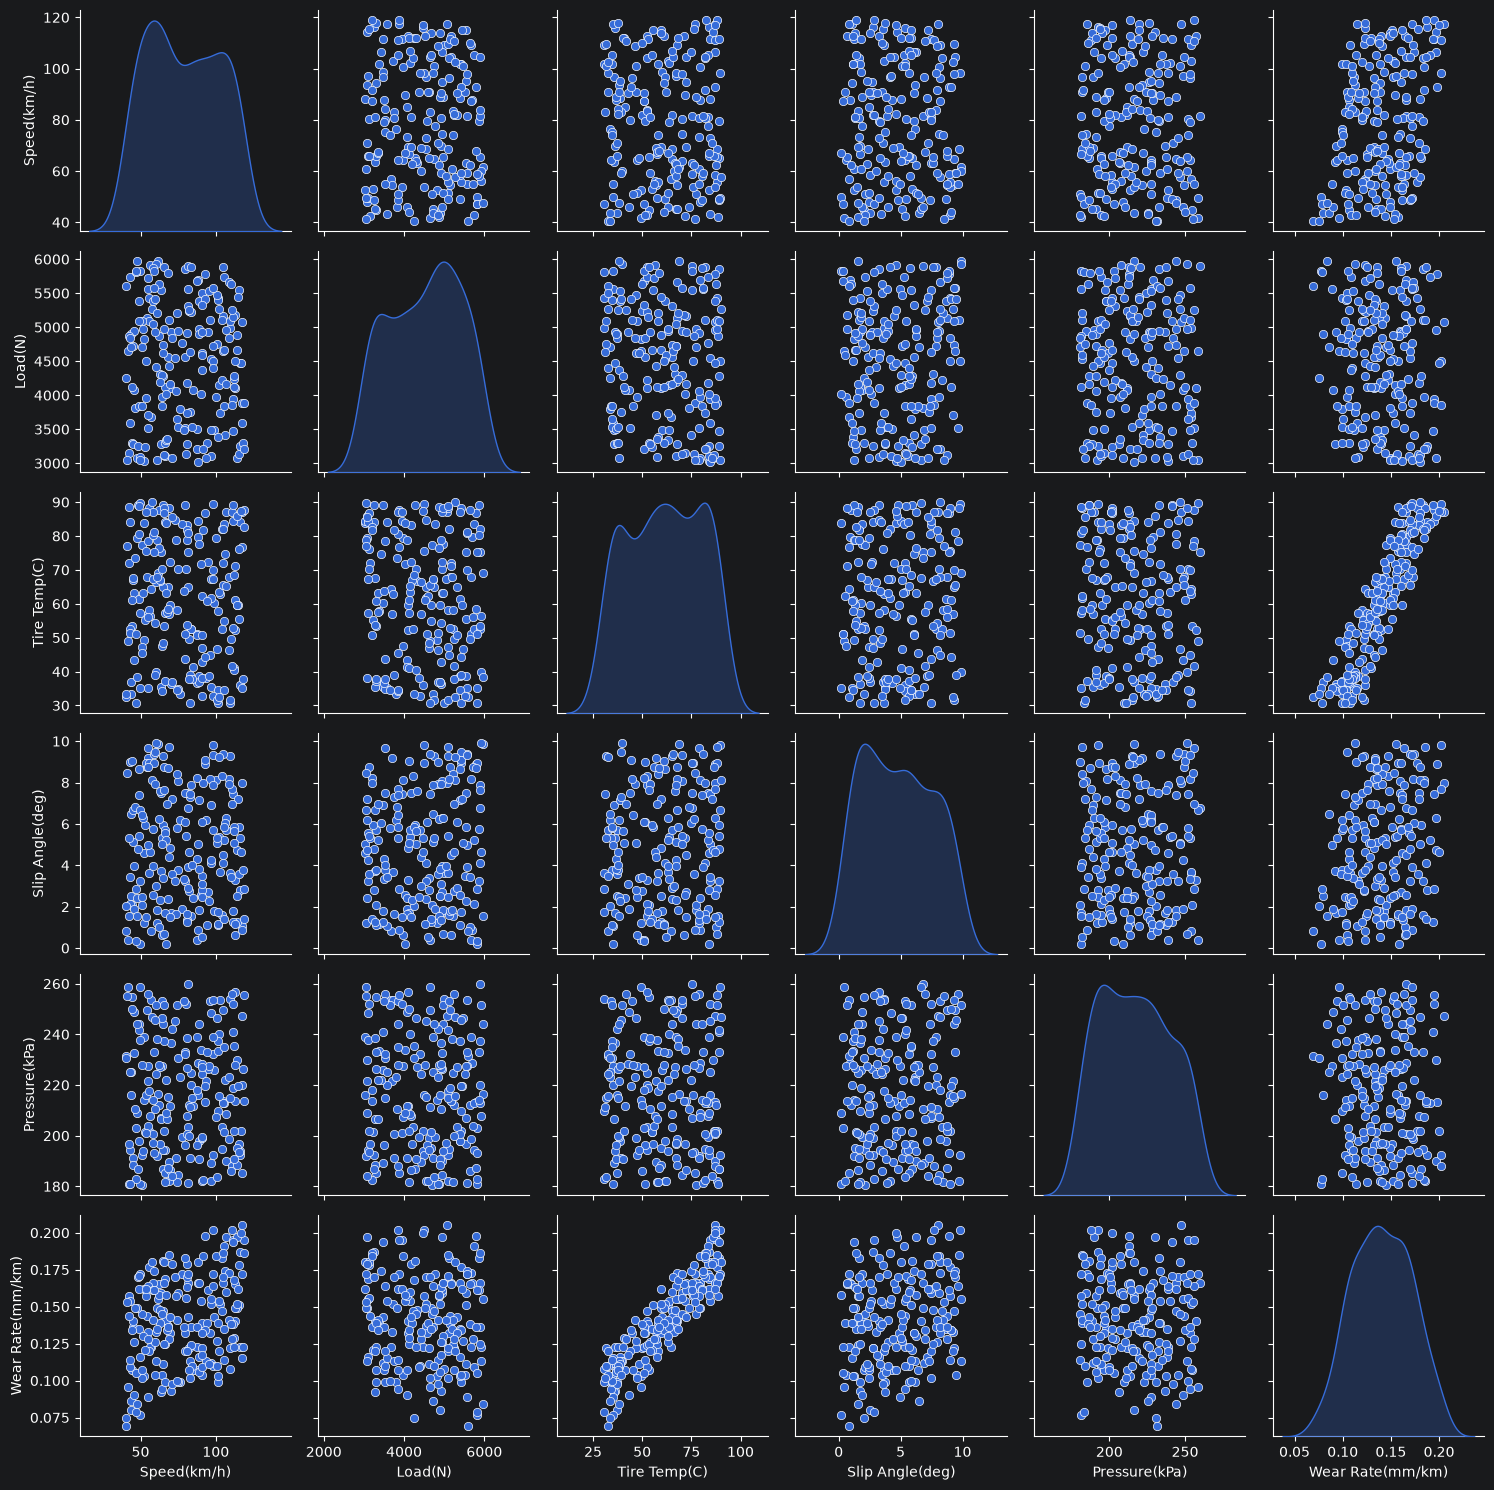

In [11]:
#Feature Engineering
#Viewing to see the dataset distribution in order to decide the scaler
plt.figure(figsize=(20,15))
sns.pairplot(tire_wear,diag_kind="kde")
plt.tight_layout();

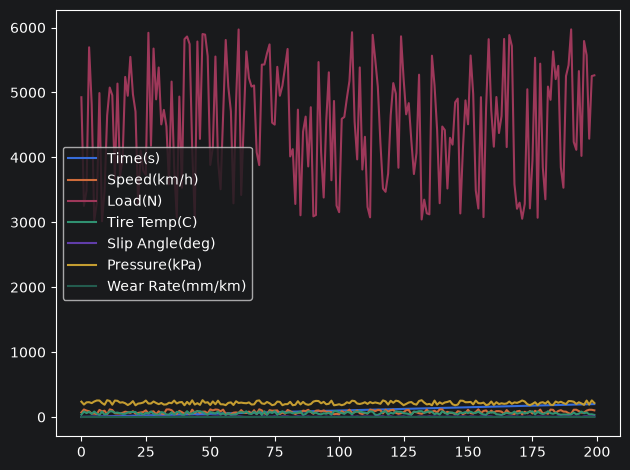

In [12]:
#Visualization of the dataset in one graph
tire_wear.plot()
plt.tight_layout();

In [13]:
#Duplicate of the worked dataset and view before scaling
tire_wear_copy1 = tire_wear.copy()
tire_wear_copy1.head()

,Time(s),Speed(km/h),Load(N),Tire Temp(C),Slip Angle(deg),Pressure(kPa),Wear Rate(mm/km)
0,0 days 00:00:00,69.963,4926.095,36.187,1.689,236.579,0.093
1,0 days 00:00:01,116.057,3252.420,84.153,2.786,192.203,0.187
2,0 days 00:00:02,98.560,3484.886,60.315,1.770,226.103,0.143
3,0 days 00:00:03,87.893,5695.663,79.587,0.887,228.537,0.166
4,0 days 00:00:04,52.481,4819.287,49.203,1.206,213.930,0.103


In [14]:
#Importing and using the minmax scaler
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
tire_scaled = scaler.fit_transform(tire_wear.drop("Time(s)",axis=1))

In [15]:
#Converting to dataframe
tire_scaled_df = pd.DataFrame(tire_scaled,columns=tire_wear.drop("Time(s)",axis=1).columns)

In [16]:
#View of the dataset
tire_scaled_df.head()

,Speed(km/h),Load(N),Tire Temp(C),Slip Angle(deg),Pressure(kPa),Wear Rate(mm/km)
0,0.376021,0.646379,0.093321,0.155160,0.708097,0.176471
1,0.963138,0.080246,0.901741,0.268032,0.149057,0.867647
2,0.740272,0.158880,0.499975,0.163494,0.576122,0.544118
3,0.604402,0.906691,0.824786,0.072641,0.606785,0.713235
4,0.153345,0.610251,0.312693,0.105464,0.422769,0.250000


<Figure size 2000x1500 with 0 Axes>

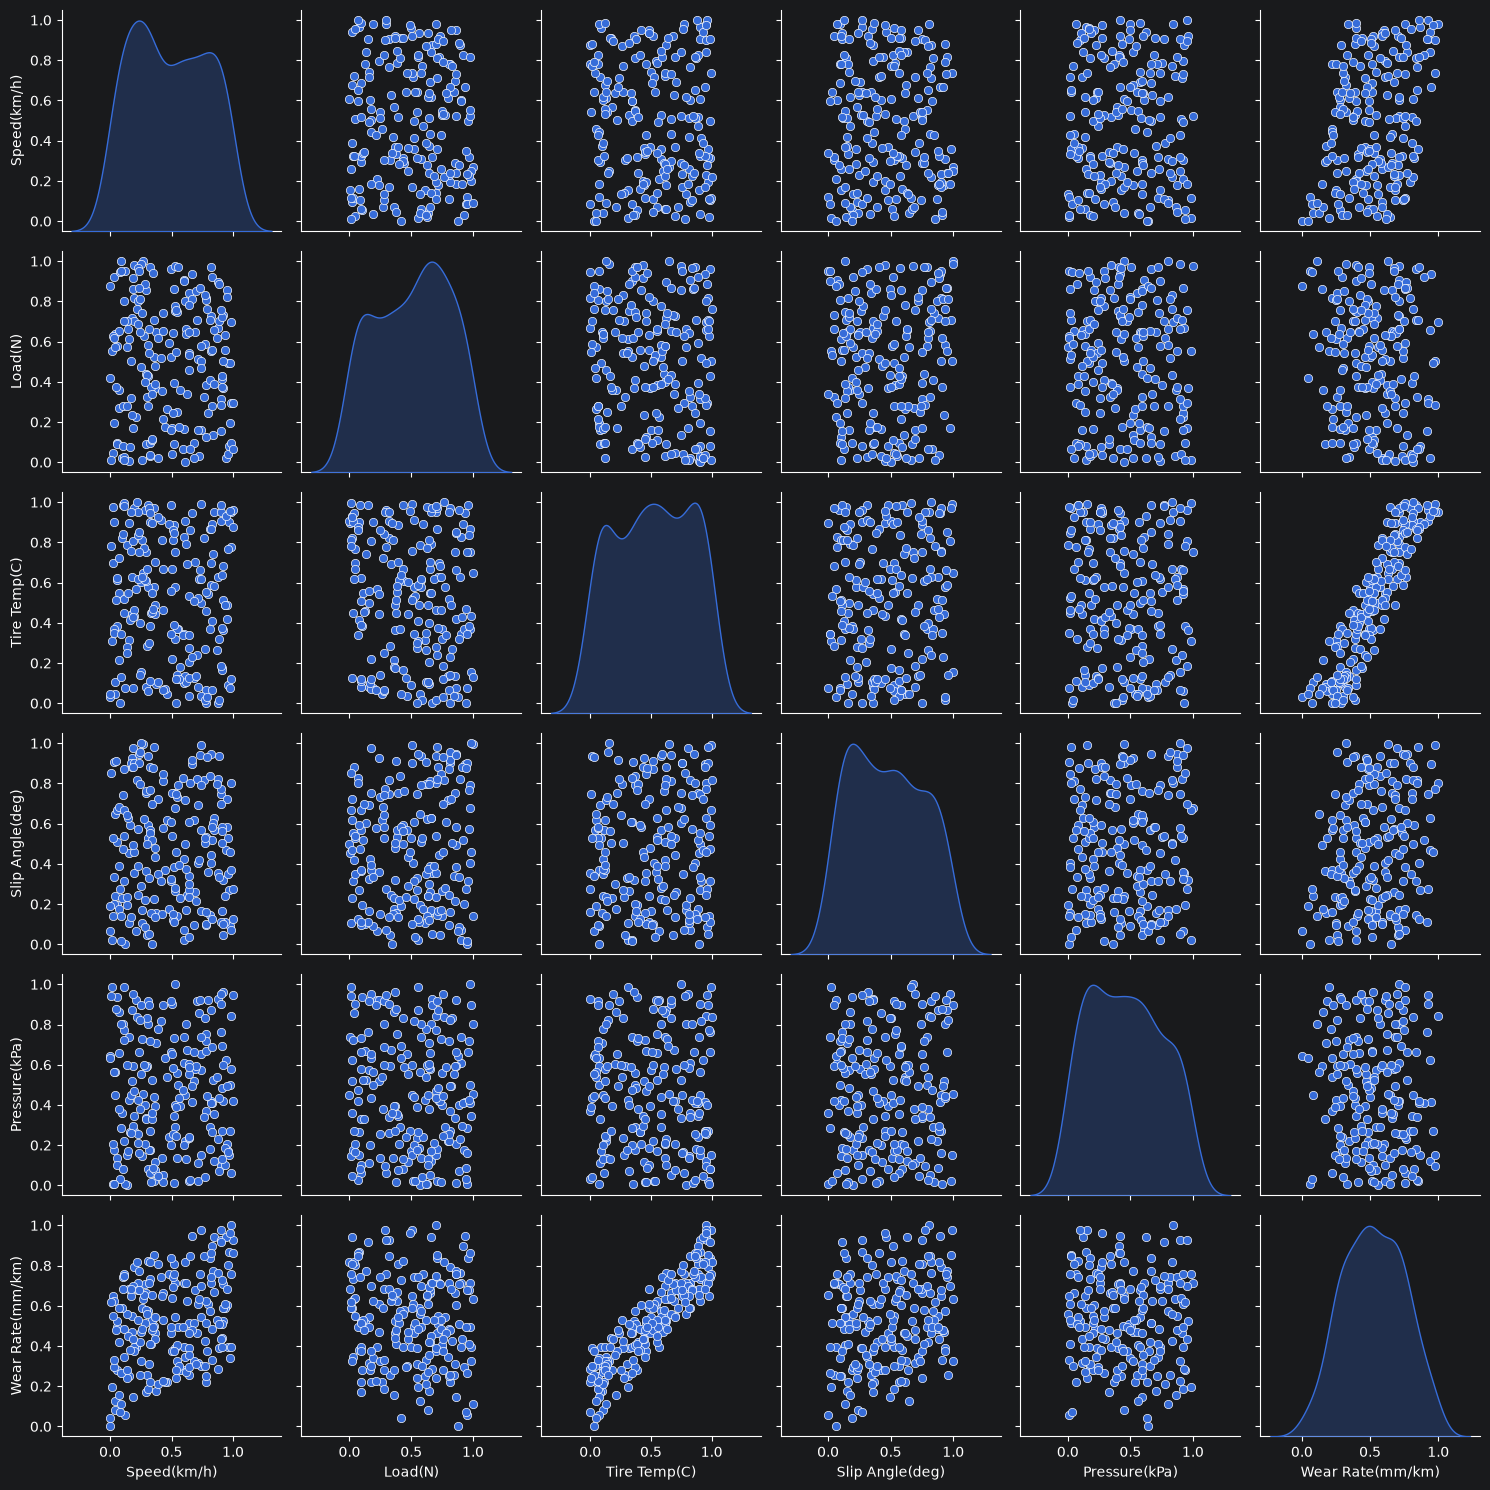

In [17]:
#Visualization of the scaled dataset
plt.figure(figsize=(20,15))
sns.pairplot(tire_scaled_df,diag_kind="kde")
plt.tight_layout();

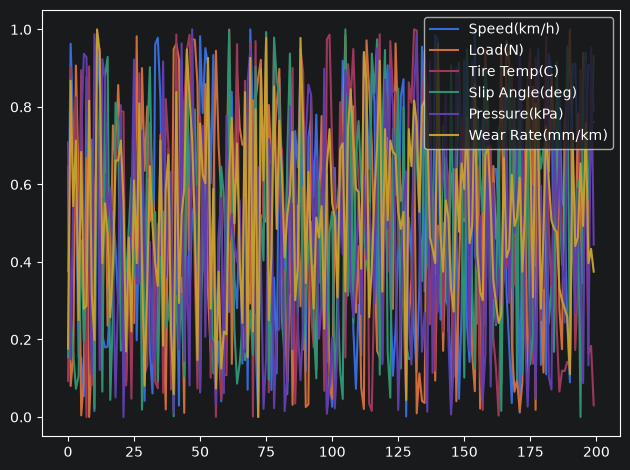

In [18]:
#Verification of the scaled dataset
tire_scaled_df.plot()
plt.tight_layout();

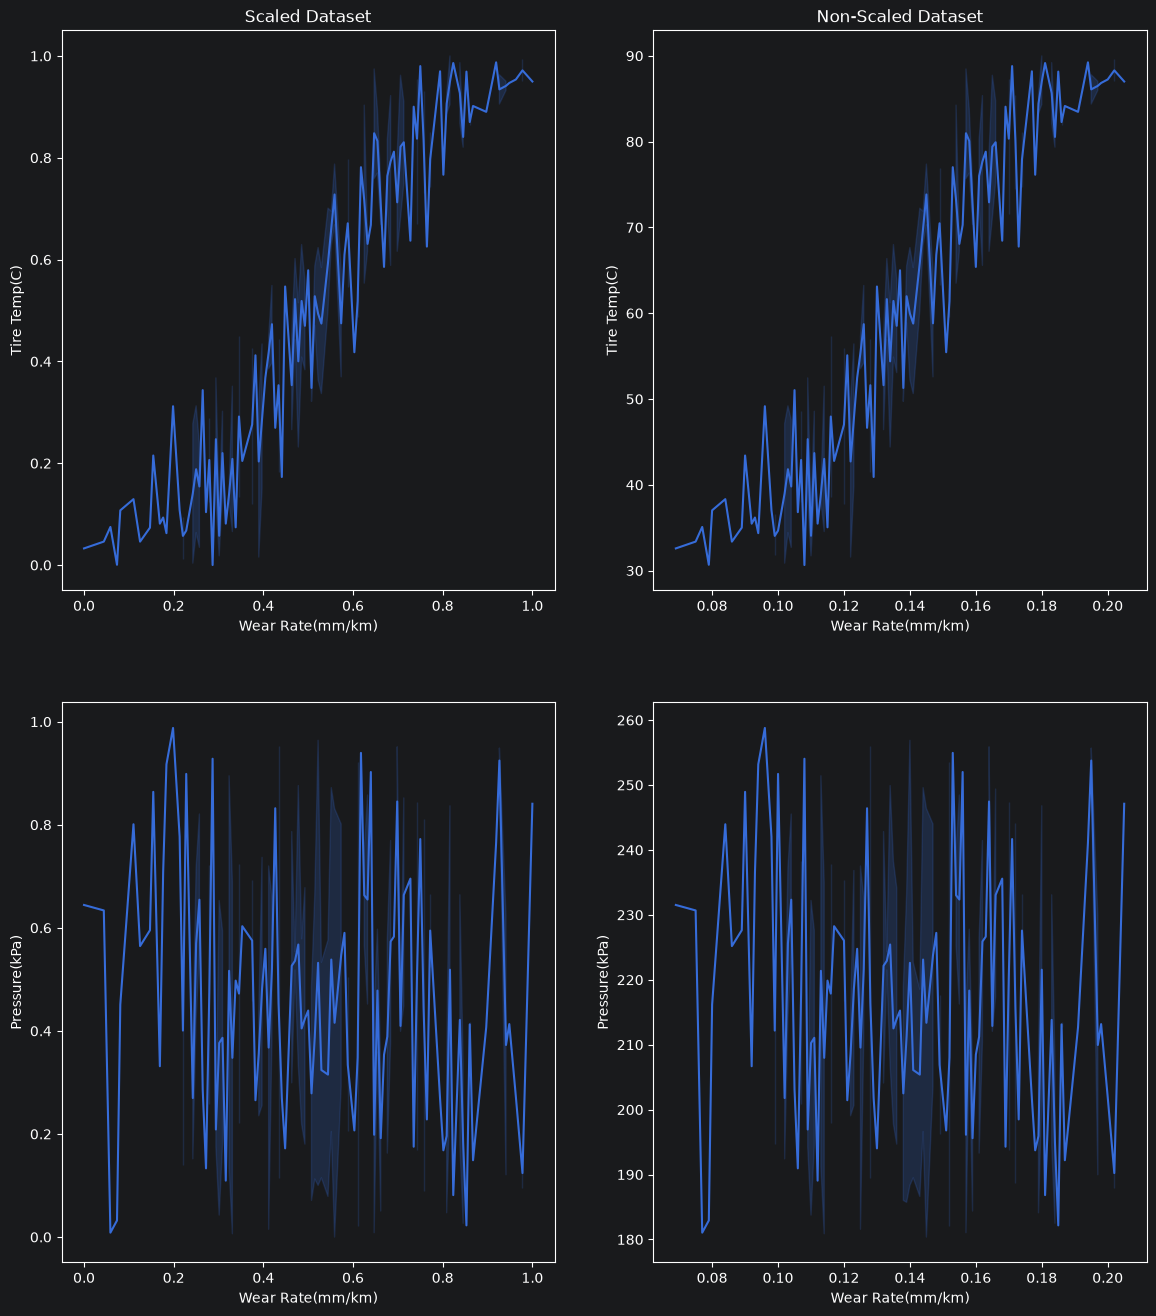

In [25]:
#Visualizing scaled and non-scaled dataset to note any observation
fig,axes = plt.subplots(2, 2, figsize=(14, 16))

sns.lineplot(data=tire_scaled_df,x=tire_scaled_df.columns[5],y=tire_scaled_df.columns[2],ax=axes[0,0])
axes[0,0].set_title("Scaled Dataset")

sns.lineplot(data=tire_wear,x=tire_wear.columns[6],y=tire_wear.columns[3], ax=axes[0,1])
axes[0,1].set_title("Non-Scaled Dataset")

sns.lineplot(data=tire_scaled_df,x=tire_scaled_df.columns[5],y=tire_scaled_df.columns[4],ax=axes[1,0])

sns.lineplot(data=tire_wear,x=tire_wear.columns[6],y=tire_wear.columns[5], ax=axes[1,1]);